<img src="img3/Banner Curso 3_.jpg" width="921" height="89" align="center"/>

<h1><center>Deep Learning - AnáhuacX</center></h1>
<h2><center>Actividad 3: Reconocimiento de letras manuscritas</center></h2>


<p style='text-align: justify;'>El siguiente ejercicio tiene como objetivo que practiques la construcción de redes neuronales convolucionales. </p>
    
<p style='text-align: justify;'>Estas redes generalmente son utilizadas para la optimización del reconocimiento de imágenes utilizando aprendizaje profundo. Trabajaremos con una base de datos que posee datos preprocesados de imágenes tomadas a letras manuscritas. </p>

<p style='text-align: justify;'>Es importante que tomes en cuenta que, para efectos de control del ejercicio, hemos colocado semillas que regulan la aleatorización de los procesos en el algoritmo. De esta manera nos aseguramos que todos obtengan el mismo resultado si el algoritmo se escribe correctamente.</p>

<p style='text-align: justify;'>Te invitamos a que experimentes con tu cuaderno después de contestar el cuestionario de la plataforma y retires estas semillas. Observa como se comportan tus redes convolucionales y revisa si mejoran o empeoran a la hora de agregarle la aleatoriedad característica de las redes neuronales.</p>

<p style='text-align: justify;'>Te compartimos la siguiente cita, de la cual obtuvimos la base de datos utilizada para esta actividad.</p>

<p style='text-align:center;'><strong>Gupta, A. (2018). <em>Handwritten A-Z</em>. Kaggle. <a href="https://www.kaggle.com/ashishguptajiit/handwritten-az" target="_blank">https://www.kaggle.com/ashishguptajiit/handwritten-az</a></strong></p>
  
<p style='text-align: justify;'><strong>Al finalizar deberás subir tu cuaderno en un archivo .zip</strong>.</p> 
  
  <p style='text-align: justify;'>Es muy importante que subas tu cuaderno de la manera en cómo te indicamos para que tus compañeros puedan revisar tu código.</p>

<ol>
    <li>Carga las siguientes librerías: </li>
</ol>

In [1]:
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread
import numpy as np
from scipy import signal
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
%matplotlib inline

from numpy.random import seed
seed(30) ## No muevas este parámetro, nos aseguramos de que tus resultados (si haces bien el ejercicio) 
         ## estén alineados con las opciones de la plataforma de edX.

<ol start=2>
    <li>Carga tus datos e imprime los primeros 5 elementos del conjunto: </li>
</ol>

In [2]:
df = pd.read_csv('handwritten_data_785.csv')
print("Las columnas del conjunto de datos son: ", df.columns)

Las columnas del conjunto de datos son:  Index(['0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8', '0.9',
       ...
       '0.562', '0.563', '0.564', '0.565', '0.566', '0.567', '0.568', '0.569',
       '0.570', '0.571'],
      dtype='str', length=785)


In [3]:
print("El conjunto de datos  tiene {} filas y {} columnas".format(df.shape[0],df.shape[1]))
df.head(5)

El conjunto de datos  tiene 372037 filas y 785 columnas


,0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,...,0.562,0.563,0.564,0.565,0.566,0.567,0.568,0.569,0.570,0.571
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


<ol start=3>
    <li>Genera una muestra probabilística tomando en cuenta todos los datos, para ello tendrás que revolver los elementos. Después, imprime los primeros cinco elementos y responde, <strong>¿Cuál es el elemento de la primera fila, primera columna?</strong></li>
</ol>

In [4]:
df_shuffled = df.sample(frac=1, random_state=30)
print(df_shuffled.head(5))
print("Primera fila, primera columna:", df_shuffled.iloc[0, 0])

         0  0.1  0.2  0.3  0.4  0.5  0.6  0.7  0.8  0.9  ...  0.562  0.563  \
189426  14    0    0    0    0    0    0    0    0    0  ...      0      0   
359997  24    0    0    0    0    0    0    0    0    0  ...      0      0   
172604  14    0    0    0    0    0    0    0    0    0  ...      0      0   
300870  19    0    0    0    0    0    0    0    0    0  ...      0      0   
87360    9    0    0    0    0    0    0    0    0    0  ...      0      0   

        0.564  0.565  0.566  0.567  0.568  0.569  0.570  0.571  
189426      0      0      0      0      0      0      0      0  
359997      0      0      0      0      0      0      0      0  
172604      0      0      0      0      0      0      0      0  
300870      0      0      0      0      0      0      0      0  
87360       0      0      0      0      0      0      0      0  

[5 rows x 785 columns]
Primera fila, primera columna: 14


<ol start = 4>
    <li>Separa la variable objetivo de tu conjunto de datos. Recuerda que aquí se definen las variables dependientes e independientes.</li>
</ol>

In [5]:
# X: Todas las filas (:), desde la segunda columna en adelante (1:) -> 784 columnas
X = df_shuffled.iloc[:, 1:]

# y: Todas las filas (:), solo la primera columna (0) -> 1 serie/vector objetivo
y = df_shuffled.iloc[:, 0]

In [6]:
print("Forma de X (independientes):", X.shape)  # Debe ser (372037, 784)
print("Forma de y (dependiente):", y.shape)     # Debe ser (372037,)

Forma de X (independientes): (372037, 784)
Forma de y (dependiente): (372037,)


<ol start=5>
    <li>Realiza una normalización de los datos encontrados en la variable independiente. La normalización se debe dar para convertir los números a valores entre 0 y 1. Recuerda que el valor máximo encontrado en los elementos de esta variable es <strong>255</strong>.</li>
</ol>

In [7]:
X = X.values
X = X / 255.0

<ol start = 6>
    <li>Ejecuta las siguientes líneas. Te ayudarán a generar una biblioteca que te permita reemplazar los números con los cuales se relacionan las letras de las fotografías.</li>
</ol>

In [8]:
abc = [chr(65+i) for i in np.unique(y)]
print(abc)

['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


In [9]:
letters_map = dict(zip(np.unique(y), range(len(np.unique(y)))))
letters_map

{0: 0,
 1: 1,
 2: 2,
 3: 3,
 4: 4,
 5: 5,
 6: 6,
 7: 7,
 8: 8,
 9: 9,
 10: 10,
 11: 11,
 12: 12,
 13: 13,
 14: 14,
 15: 15,
 16: 16,
 17: 17,
 18: 18,
 19: 19,
 20: 20,
 21: 21,
 22: 22,
 23: 23,
 24: 24,
 25: 25}

In [10]:
y = y.replace(letters_map).values

<ol start = 7>
    <li>Realiza un <em>reshape</em> de la variable independiente de tal forma que resulte una matriz de 28 x 28.</li>
</ol>

In [11]:
X = X.reshape((-1,28,28,1))

<ol start=8>
    <li>Ejectura la siguiente línea de código para imprimir las primeras cinco letras de nuestra base de datos y responde: <strong>¿Cuál es la segunda letra de la primera fila?</strong></li>
</ol>

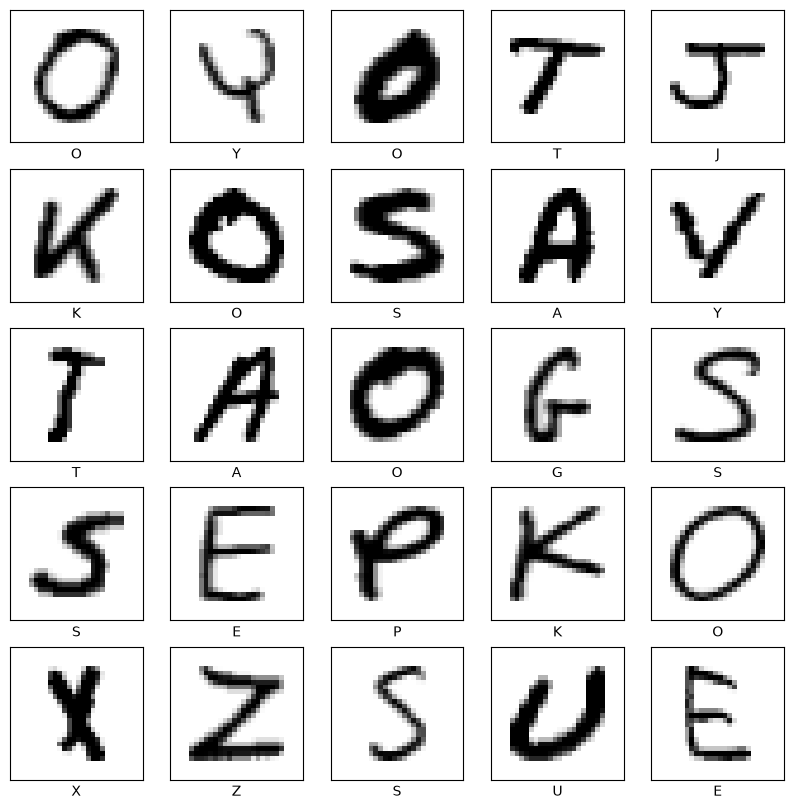

In [12]:
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    number = X[i].reshape(28,28)
    plt.imshow(number, cmap=plt.cm.binary)
    plt.xlabel(abc[y[i]])
plt.show()

<ol start=9>
    <li>Realiza el <em>split</em> de datos en conjuntos de <strong>entrenamiento</strong> y <strong>prueba</strong> de las variables independiente y dependiente. Realiza la separación de datos de tal forma que 70% se vayan a los conjuntos de entrenamiento y el restante a los de prueba. Por último, define un random state con valor de <strong>103</strong>.</li>
</ol>

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=103)

In [14]:
X_train.shape

(260425, 28, 28, 1)

<ol start = 10>
    <li>Genera dos capas de redes convolucionales. Recuerda que cada capa convolucional lleva una capa de agrupacion. </li>
<p>Las características de la primera capa convolucional son las siguientes:<p>
    <ol>
        <li>Filtros: <strong>32</strong>.</li>
        <li>Tamaño del kernel: <strong>5 x 5</strong>.</li>
        <li>Señal de activación: <strong>Relu</strong>.</li>
        <li>Padding: <strong>same</strong>.</li>
        <li>Input shape: <strong>28 x 28 x 1</strong>.</li>
    </ol>

<p>Las características de la segunda capa de convolución son las siguientes:</p>
        <ol>
            <li>Filtros: <strong>64</strong>.</li>
            <li>Tamaño del kernel: <strong>5 x 5</strong>.</li>
            <li>Señal de activación: <strong>Relu</strong>.</li>
            <li>Padding: <strong>same</strong>.</li>
            <li>Input shape: <strong>input_layer</strong>.</li>
        </ol>
        
<p>Las características de las capas de agrupamiento (MaxPooling) son las siguientes:</p>
        <ol>
            <li>Pool size = <strong>2 x 2</strong>.</li>
            <li>Stride = <strong>2</strong></li>
        </ol>
</ol>

In [15]:
import tensorflow
tensorflow.random.set_seed(30) ## No muevas este parámetro, nos aseguramos de que tus resultados (si haces bien el ejercicio) 
                               ## estén alineados con las opciones de la plataforma de edX.
from tensorflow import keras
from tensorflow.keras import datasets, layers, models
    
    
input_layer = X_train

model = models.Sequential()

# Creando Conv2D_1
model.add(
    layers.Conv2D(filters = 32, 
                  kernel_size = (5, 5),
                  activation='relu',
                  padding="same",
                  input_shape=(28,28,1,))
)

# Creando Pooling2D_1
model.add(
    layers.MaxPooling2D(pool_size = (2, 2),
                        strides=2)
)

# Creando Conv2D_2
model.add(
    layers.Conv2D(filters = 64, 
                  kernel_size = (5, 5),
                  activation='relu',
                  padding="same",
                  input_shape=input_layer.shape)
)

# Creando Pooling2D_2
model.add(
    layers.MaxPooling2D(pool_size = (2, 2),
                        strides=2)
)


model.summary()


2026-11-19 00:07:09.570762: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-19 00:07:09.643194: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-19 00:07:09.793576: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-19 00:07:09.793682: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-19 00:07:09.809921: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        832       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 64)        51264     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 64)          0         
 g2D)                                                            
                                                                 
Total params: 52096 (203.50 KB)
Trainable params: 52096 (203.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


<ol start=11>
    <li><strong>¿Cuántos parámetros está manejando la primera capa de convolución?</strong></li>
</ol>

<ol start = 12>
    <li><strong>¿Cuántos parámetros está manejando la segunda capa de convolución?</strong></li>
</ol>

<ol start = 13>
    <li>Genera:
        <ol>
            <li>Una <strong>capa de Flatten</strong>.</li>
            <li>Una <strong>red neuronal con una capa oculta</strong>.</li>
            <li>Una capa de <strong>Dropout</strong>:</li>
            <ol>
                <li>Entre la <strong>capa de entrada</strong> y la <strong>capa oculta</strong> y;</li> 
                <li>Entre la <strong>capa oculta</strong> y la <strong>capa de salida</strong>.</li>
            </ol>
        </ol>
    
<p>Las características de la red neuronal son los siguientes:<p>
    <ol>
        <li>Número de entradas: <strong>64</strong></li>
        <li>Señal de activación de la capa Flatten a la entrada de la red: <strong>Relu</strong>.</li>
        <li>Señal de activación de la capa de entrada y la capa oculta: <strong>Softmax</strong>.</li>
        <li>Señal de activación de la capa oculta y la capa de salida: <strong>Softmax</strong>.</li>
        <li>Cuida mucho el <strong>número de salidas</strong> de tu red neuronal.</li>
    </ol>

<p>El rate de las capas de <strong>Dropout</strong> es de: 0.4</p>

   
</ol>

In [16]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(32, activation='softmax'))
model.add(layers.Dropout(rate = 0.4))
model.add(layers.Dense(26, activation='softmax'))
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 32)        832       
                                                                 
 max_pooling2d (MaxPooling2  (None, 14, 14, 32)        0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 64)        51264     
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 7, 7, 64)          0         
 g2D)                                                            
                                                                 
 flatten (Flatten)           (None, 3136)              0         
                                                                 
 dense (Dense)               (None, 64)                2

<ol start = 14>
    <li><strong>¿Cuántos parámetros se están manejando en la capa de salida?</strong></li>
</ol>

<ol start = 15>
    <li>Compila el modelo generado con base en las siguientes características: </li>
    <ol>
        <li>Optimizador: <strong>adam</strong>.</li>
        <li>Loss: <strong>sparse_categorical_crossentropy</strong>.</li>
        <li>Métrica: <strong>Accuracy</strong>.</li>
    </ol>
    
 <p>Realiza un ajuste del modelo con las siguientes características: </p>
    
 <ol>
     <li>Utilizar los conjuntos de <strong>entrenamiento</strong> de las <strong>variables independientes y dependientes</strong> para ajustarse en el modelo.</li>
     <li>Validación de los datos: <strong>Conjuntos de prueba de las variables dependiente e independiente</strong>.</li>
     <li>Epochs: <strong>10</strong>.</li>
     <li>Tamaño del batch: <strong>100</strong>.</li>
 </ol>
</ol>

In [17]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, 
          validation_data = (X_test, y_test),
          epochs=10,
          batch_size = 100);

Epoch 1/10
2605/2605 [==============================] - 87s 33ms/step - loss: 2.2661 - accuracy: 0.3348 - val_loss: 1.4138 - val_accuracy: 0.6113
Epoch 2/10
2605/2605 [==============================] - 78s 30ms/step - loss: 1.6967 - accuracy: 0.4533 - val_loss: 1.0213 - val_accuracy: 0.7087
Epoch 3/10
2605/2605 [==============================] - 89s 34ms/step - loss: 1.4941 - accuracy: 0.5386 - val_loss: 0.7439 - val_accuracy: 0.8309
Epoch 4/10
2605/2605 [==============================] - 80s 31ms/step - loss: 1.3132 - accuracy: 0.5954 - val_loss: 0.5661 - val_accuracy: 0.8727
Epoch 5/10
2605/2605 [==============================] - 84s 32ms/step - loss: 1.1940 - accuracy: 0.6297 - val_loss: 0.4660 - val_accuracy: 0.8828
Epoch 6/10
2605/2605 [==============================] - 81s 31ms/step - loss: 1.0946 - accuracy: 0.6629 - val_loss: 0.3864 - val_accuracy: 0.9478
Epoch 7/10
2605/2605 [==============================] - 87s 33ms/step - loss: 0.9892 - accuracy: 0.7041 - val_loss: 0.3201 -

<ol start=16>
    <li>Ejecuta el siguiente código para evaluar tu modelo y responde a la siguiente pregunta: <strong>¿Cuál es la precisión de la red?</strong></li>
</ol>

In [18]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Test acc:", test_acc)

3488/3488 [==============================] - 24s 7ms/step - loss: 0.2097 - accuracy: 0.9675
Test acc: 0.9675034880638123


<ol start = 17>
    <li>Ejecuta las siguientes instrucciones y responde a la siguiente pregunta: <strong>¿Cuántas veces se equivocó la red?</strong></li>
</ol>

<ol start=18>
    <li><strong>¿Cuál es el porcentaje de error?</strong></li>
</ol>

In [19]:
predictions = model.predict(X_test)
y_hat = np.argmax(predictions,axis=1)

3488/3488 [==============================] - 24s 7ms/step


In [20]:
errores = X_test[y_test != y_hat]
print("Elementos de prueba: {}".format(y_test.shape[0]))
errores_count = errores.shape[0]
errores_count
print("Errores identificados: {}".format(errores_count))
porcentaje_error = errores_count *100 / y_test.shape[0]
print("Porcentaje de error: {} %".format(porcentaje_error))

Elementos de prueba: 111612
Errores identificados: 3627
Porcentaje de error: 3.249650575206967 %


<ol start=19>
    <li>Ejecuta las siguientes líneas para visualizar los elementos en los que se equivocó la red y genera tu matriz de confusión para visualizar cuáles fueron las letras en las que más se equivocó.</li>
</ol>

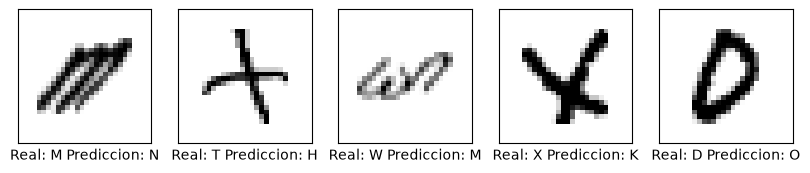

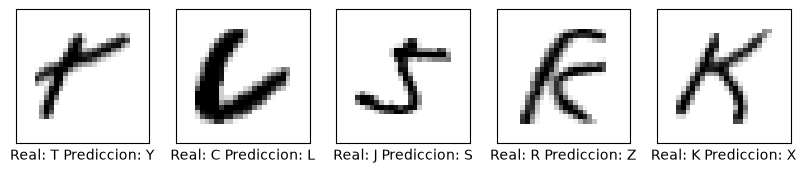

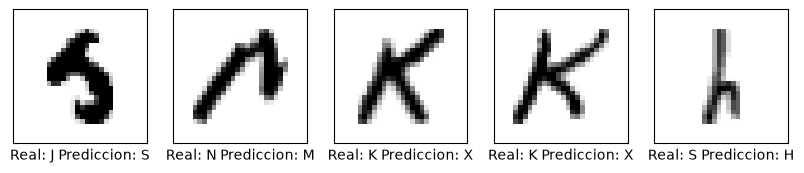

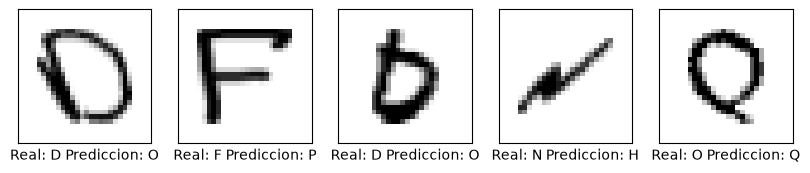

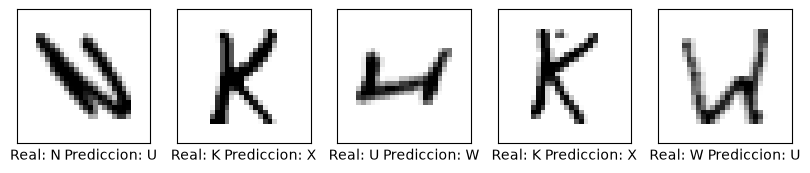

...

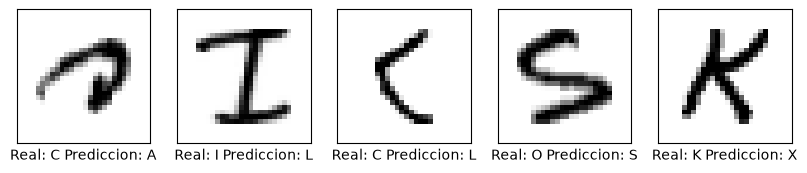

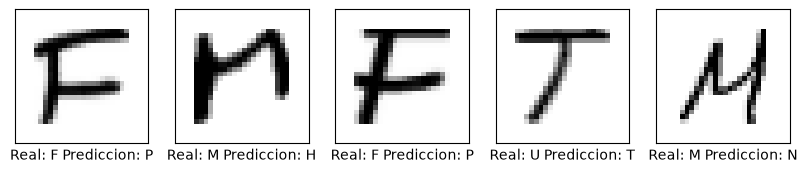

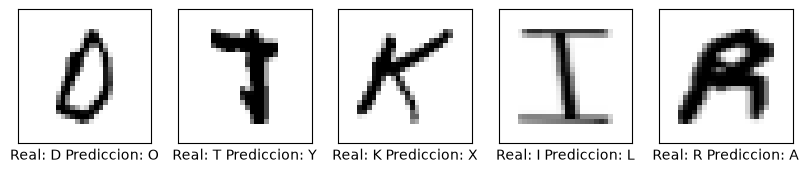

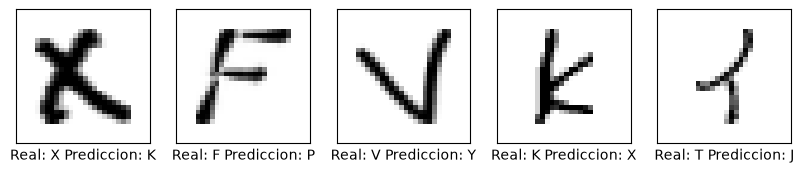

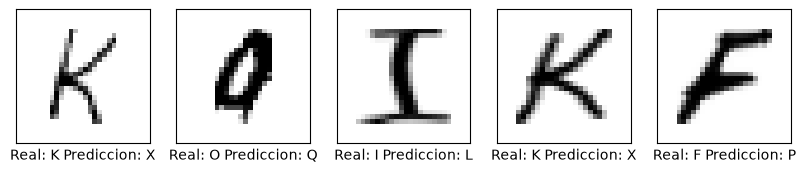

In [21]:
real_labels = y_test[y_test != y_hat]
predicted_labels = y_hat[y_test != y_hat]

for j in range(round(errores.shape[0]/5)):
    plt.figure(figsize=(10,10))
    for i in range(min(5,errores_count-5*j)):
        plt.subplot(1,min(5,errores_count-5*j),i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        number = errores[5*j+i].reshape(28,28)
        plt.imshow(number, cmap=plt.cm.binary)
        plt.xlabel("Real: {} Prediccion: {}".format
                   (abc[real_labels[5*j+i]],abc[predicted_labels[5*j+i]]))
    plt.show()

ValueError: The number of FixedLocator locations (10), usually from a call to set_ticks, does not match the number of labels (26).

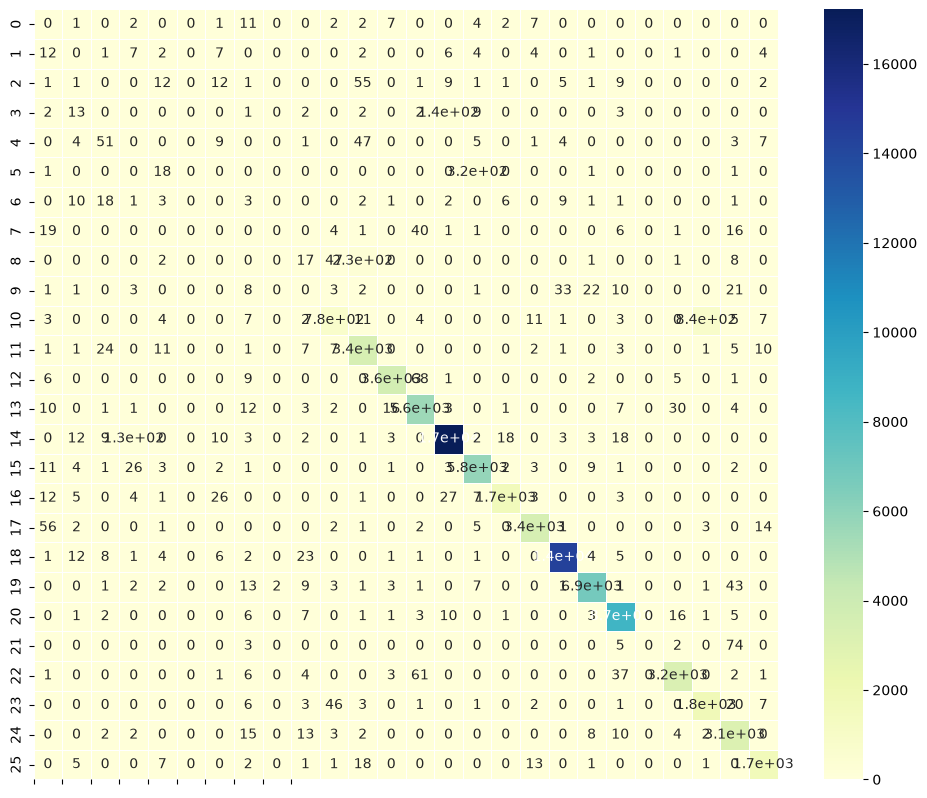

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

mod_confusion_matrix = confusion_matrix(y_test, y_hat)
for i in range(26):
    mod_confusion_matrix[i][i] = 0
    
fig = plt.figure(figsize=(12,10))
ax = fig.add_subplot(1,1,1) 
sns.heatmap(mod_confusion_matrix, linewidth=0.5, annot=True, cmap="YlGnBu")
plt.xticks(np.arange(26), abc)
plt.yticks(np.arange(26), abc)
plt.ylabel("Etiquetas Reales")
plt.xlabel("Etiquetas Predecidas")
ax.set_ylim(26.5,-0.5);

<ol start=20>
    <li><strong>¿Cuáles son las tres letras que la red predijo de manera incorrecta</strong>.</li>
</ol>

<img src="img3/Anáhuac_edX.png" width="498" height="150" align="center"/>